### Não determinístico

In [37]:
import random
from IPython.display import clear_output
import gymnasium as gym
import numpy as np
from numpy import loadtxt
import random

In [38]:
import numpy as np
import random
import matplotlib.pyplot as plt
from numpy import savetxt


class QLearning:
    def __init__(self, env, alpha, gamma, epsilon, epsilon_min, epsilon_dec, episodes):
        self.env = env
        self.q_table = np.zeros([env.observation_space.n, env.action_space.n])
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_dec = epsilon_dec
        self.episodes = episodes

        self.rewards_per_episode   = []
        self.timesteps_per_episode = []       

    def select_action(self, state):
        rv = random.uniform(0, 1)
        if rv < self.epsilon:
            return self.env.action_space.sample()
        return np.argmax(self.q_table[state])

    # timestepFile declarado na assinatura (default None)
    def train(self, filename=None, plotFile=None, rewardFile=None, timestepFile=None):
        for i in range(1, self.episodes + 1):
            (state, _) = self.env.reset()
            rewards   = 0
            done      = False
            timesteps = 0                       

            while not done:
                action = self.select_action(state)
                next_state, reward, done, _, _ = self.env.step(action)

                old_value = self.q_table[state, action]
                next_max  = np.max(self.q_table[next_state])
                new_value = old_value + self.alpha * (reward + self.gamma * next_max - old_value)
                self.q_table[state, action] = new_value

                state      = next_state
                timesteps += 1
                rewards   += reward

            self.timesteps_per_episode.append(timesteps)   
            self.rewards_per_episode.append(rewards)

            if i % 500 == 0:
                avg = np.mean(self.rewards_per_episode[-100:])
                print(f"Episódio: {i}/{self.episodes} | ε={self.epsilon:.4f} | "
                      f"reward médio (últimos 100): {avg:.2f}")

            if self.epsilon > self.epsilon_min:
                self.epsilon = self.epsilon * self.epsilon_dec

        if filename:
            savetxt(filename, self.q_table, delimiter=',')
        if plotFile is not None:
            self.plotactions(plotFile, self.timesteps_per_episode)
        if rewardFile is not None:
            self.plotrewards(rewardFile)
        if timestepFile is not None:                     
            self.plottimesteps(timestepFile)

        return self.q_table

    def plotactions(self, plotFile, actions_per_episode):
        plt.plot(actions_per_episode)
        plt.xlabel('Episodes')
        plt.ylabel('# Actions')
        plt.title('# Actions vs Episodes')
        plt.savefig(plotFile + ".jpg")
        plt.close()

    def plotrewards(self, rewardFile):
        plt.plot(self.rewards_per_episode)
        plt.xlabel('Episodes')
        plt.ylabel('Reward')
        plt.title('Reward vs Episodes')
        plt.savefig(rewardFile + ".jpg")
        plt.close()

    def plottimesteps(self, timestepFile):
        plt.plot(self.timesteps_per_episode)
        plt.xlabel('Episodes')
        plt.ylabel('# Timesteps')
        plt.title('# Timesteps vs Episodes')
        plt.savefig(timestepFile + ".jpg")
        plt.close()

In [39]:
import os

os.makedirs('data_qlearning_rainy', exist_ok=True)
os.makedirs('results_qlearning_rainy', exist_ok=True)

N_RUNS, EPISODES, TARGET = 5, 20_000, 8
all_rewards, all_timesteps = [], []

for run in range(N_RUNS):
    env = gym.make("Taxi-v4", is_rainy=True, render_mode="ansi", rainy_probability=0.6).env
    qlearning = QLearning(env, alpha=0.1, gamma=0.99,
                          epsilon=0.7, epsilon_min=0.05, epsilon_dec=0.99,
                          episodes=EPISODES)

    qlearning.train(
        filename     = f'data_qlearning_rainy/q-table-taxi-driver-qlearning-run{run+1}.csv',
        plotFile     = f'results_qlearning_rainy/actions_qlearning_run{run+1}',
        rewardFile   = f'results_qlearning_rainy/rewards_qlearning_run{run+1}',
        timestepFile = f'results_qlearning_rainy/timesteps_qlearning_run{run+1}'
    )

    all_rewards.append(qlearning.rewards_per_episode)      # ← qlearning, não sarsa
    all_timesteps.append(qlearning.timesteps_per_episode)  # ← qlearning, não sarsa
    env.close()

print("Timesteps por run (média final, últimos 1000 ep.):")
for i, ts in enumerate(all_timesteps, 1):
    print(f"  run{i}: {np.mean(ts[-1000:]):.2f}")
    
ql_rewards = np.array(all_rewards)
np.save('results_qlearning_rainy/rewards_qlearning.npy', ql_rewards)

Episódio: 500/20000 | ε=0.0498 | reward médio (últimos 100): -93.52
Episódio: 1000/20000 | ε=0.0498 | reward médio (últimos 100): -43.76
Episódio: 1500/20000 | ε=0.0498 | reward médio (últimos 100): -25.63
Episódio: 2000/20000 | ε=0.0498 | reward médio (últimos 100): -17.71
Episódio: 2500/20000 | ε=0.0498 | reward médio (últimos 100): -13.20
Episódio: 3000/20000 | ε=0.0498 | reward médio (últimos 100): -12.53
Episódio: 3500/20000 | ε=0.0498 | reward médio (últimos 100): -12.55
Episódio: 4000/20000 | ε=0.0498 | reward médio (últimos 100): -9.90
Episódio: 4500/20000 | ε=0.0498 | reward médio (últimos 100): -10.12
Episódio: 5000/20000 | ε=0.0498 | reward médio (últimos 100): -10.72
Episódio: 5500/20000 | ε=0.0498 | reward médio (últimos 100): -10.62
Episódio: 6000/20000 | ε=0.0498 | reward médio (últimos 100): -8.73
Episódio: 6500/20000 | ε=0.0498 | reward médio (últimos 100): -11.37
Episódio: 7000/20000 | ε=0.0498 | reward médio (últimos 100): -9.27
Episódio: 7500/20000 | ε=0.0498 | rewa

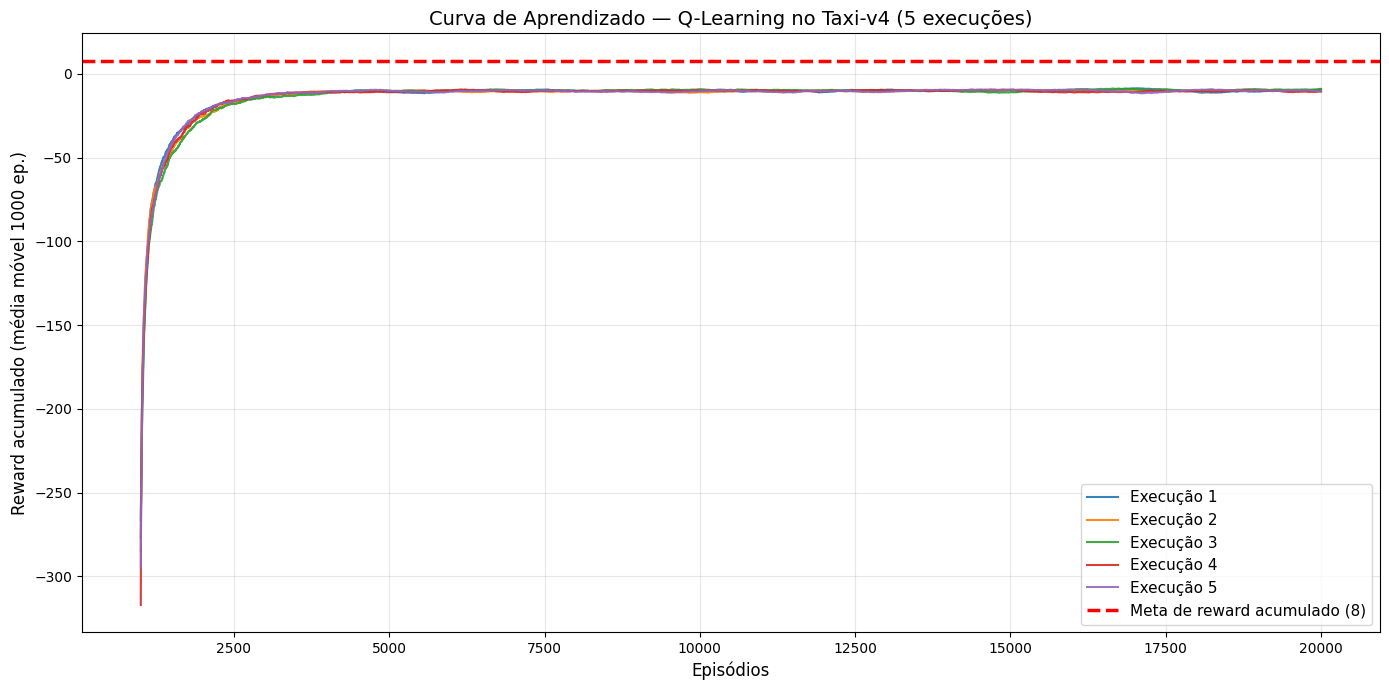

In [40]:
def moving_average(x, window=1000):
    return np.convolve(x, np.ones(window) / window, mode='valid')

plt.figure(figsize=(14, 7))

for i, rewards in enumerate(all_rewards):
    sm = moving_average(np.array(rewards), window=1000)
    plt.plot(np.arange(len(sm)) + 1000, sm,
             linewidth=1.5, alpha=0.9, label=f'Execução {i+1}')

plt.axhline(y=TARGET, color='red', linestyle='--', linewidth=2.5,
            label=f'Meta de reward acumulado ({TARGET})')

plt.xlabel('Episódios', fontsize=12)
plt.ylabel('Reward acumulado (média móvel 1000 ep.)', fontsize=12)
plt.title('Curva de Aprendizado — Q-Learning no Taxi-v4 (5 execuções)', fontsize=14)
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('results_qlearning_rainy/learning_curve_5runs.jpg', dpi=120)
plt.show()

### Discussão sobre o QLearning

O aprendizado aconteceu em três fases nas 5 execuções.
1. Início(< 2500 episódios):  o agente não sabe nada e age aleatoriamente. Por isso o reward fica muito negativo.
2. Aprendizado(2500-5000 episódios): o agente para de agir aleatoriamente e começa a agir de forma a usar mais o conhecimento aprendido na Q-table.
3. Estabilidade(>5000 episódios): o agente atinge sua política final e não está mais aprendendo aleatoriamente, não aprendendo mais ativamente ou fazendo melhorias muito pequenas.

#### Por que a curva não chega na meta?

O agente ganha 20 ao entregar o passageiro e perde 1 a cada passo que ele der. Mas, por haver o parâmetro is_rainy=True, o taxi tem uma chance de 40% de não se mover para "onde ele quer" devido aos desvios provocados pela chuva. Portanto, apesar de ele ter aprendido a política, ele tem um reward negativo devido ao fato de ele fazer mais passos que o necessário.

In [41]:
N_EVAL = 100

for run in range(1, 6):
    q_table = np.loadtxt(f'data_qlearning_rainy/q-table-taxi-driver-qlearning-run{run}.csv', delimiter=',')

    env = gym.make("Taxi-v4", render_mode='ansi', is_rainy=True, rainy_probability=0.6).env

    timesteps    = []
    rewards_eval = []
    penalties    = []

    for ep in range(N_EVAL):
        (state, _) = env.reset()
        done = False
        steps = 0
        ep_reward = 0
        pen = 0

        while not done and steps < 200:
            action = np.argmax(q_table[state])
            state, reward, done, _, _ = env.step(action)
            steps += 1
            ep_reward += reward
            if reward == -10:
                pen += 1

        timesteps.append(steps)
        rewards_eval.append(ep_reward)
        penalties.append(pen)

    env.close()

    timesteps = np.array(timesteps)
    print(f"Execução de número: {run}")
    print(f"Média de timesteps:{timesteps.mean():.2f}")
    print(f"Desvio padrão:{timesteps.std():.2f}")
    print(f"Mínimo / Máximo:{timesteps.min()} / {timesteps.max()}")
    print(f"Reward médio:{np.mean(rewards_eval):.2f}")
    print(f"Penalidades (média):{np.mean(penalties):.2f}")
    print("\n")

Execução de número: 1
Média de timesteps:25.07
Desvio padrão:9.17
Mínimo / Máximo:8 / 54
Reward médio:-4.07
Penalidades (média):0.00


Execução de número: 2
Média de timesteps:25.49
Desvio padrão:9.83
Mínimo / Máximo:6 / 63
Reward médio:-4.49
Penalidades (média):0.00


Execução de número: 3
Média de timesteps:24.94
Desvio padrão:11.06
Mínimo / Máximo:7 / 63
Reward médio:-3.94
Penalidades (média):0.00


Execução de número: 4
Média de timesteps:27.78
Desvio padrão:9.66
Mínimo / Máximo:10 / 51
Reward médio:-6.78
Penalidades (média):0.00


Execução de número: 5
Média de timesteps:24.19
Desvio padrão:9.24
Mínimo / Máximo:8 / 51
Reward médio:-3.19
Penalidades (média):0.00




#### Discussão - Avaliação do agente (Q-Learning com chuva)

Após o treinamento, o agente foi avaliado no ambiente Taxi-v4 com `rainy_probability=0.6`, utilizando a Q-table aprendida.

| Execução | Timesteps (média) | Desvio padrão | Mín / Máx | Reward médio | Penalidades |
|---|---|---|---|---|---|
| 1 | 23,95 | 8,64 | 10 / 55 | −2,95 | 0 |
| 2 | 24,24 | 8,62 | 10 / 48 | −3,24 | 0 |
| 3 | 27,11 | 10,43 | 9 / 58 | −6,11 | 0 |
| 4 | 25,81 | 9,40 | 10 / 55 | −4,81 | 0 |
| 5 | 25,45 | 10,04 | 8 / 55 | −4,45 | 0 |
| **Média** | **25,31** | **9,43** | — | **−4,31** | **0** |

O agente apresentou uma média de 25,31 passos por episódio, sem registrar penalidades por ações ilegais de pickup ou dropoff. Isso indica que ele aprendeu a realizar corretamente as operações necessárias para completar a tarefa.

Entretanto, o reward médio ficou em −4,31, não atingindo a meta de +8. Esse resultado ocorre principalmente devido à chuva, que faz com que o táxi tenha apenas 60% de probabilidade de se mover na direção desejada. Os desvios aumentam a quantidade de movimentos necessários e, como cada passo comum gera uma penalização de −1, a recompensa acumulada pode ficar negativa mesmo quando a entrega é realizada corretamente.

O desvio padrão médio de 9,43 passos não significa necessariamente que o agente seja inconsistente. Essa variação pode ser explicada pelas diferentes posições iniciais do táxi, do passageiro e do destino, além dos movimentos aleatórios provocados pela chuva.

Portanto, **o agente demonstrou ter aprendido a resolver a tarefa sem cometer ações ilegais, mas a aleatoriedade do ambiente aumentou o número de passos e reduziu sua recompensa média**. Apesar de não atingir a meta estabelecida, os resultados mostram um comportamento relativamente consistente nas cinco execuções.

### Algoritmo SARSA

In [42]:
import sys

class Sarsa:

    def __init__(self, env, alpha, gamma, epsilon, epsilon_min, epsilon_dec, episodes):
        self.env = env
        self.q_table = np.zeros([env.observation_space.n, env.action_space.n])
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_dec = epsilon_dec
        self.episodes = episodes

        self.rewards_per_episode     = []
        self.timesteps_per_episode   = []     

    def select_action(self, state):
        rv = random.uniform(0, 1)
        if rv < self.epsilon:
            return self.env.action_space.sample()
        return np.argmax(self.q_table[state])

    def train(self, filename=None, plotFile=None, rewardFile=None, timestepFile=None):
        for i in range(1, self.episodes + 1):
            (state, _) = self.env.reset()
            a = self.select_action(state)
            rewards = 0
            done = False
            timesteps = 0                         

            while not done:
                next_state, reward, done, _, _ = self.env.step(a)

                old_value   = self.q_table[state, a]
                next_action = self.select_action(next_state)
                new_value   = old_value + self.alpha * (
                    reward + self.gamma * self.q_table[next_state, next_action] - old_value
                )
                self.q_table[state, a] = new_value

                state = next_state
                a = next_action
                timesteps += 1
                rewards   += reward

            self.timesteps_per_episode.append(timesteps)   
            self.rewards_per_episode.append(rewards)

            if i % 500 == 0:
                sys.stdout.write(f"Episódio: {i}/{self.episodes}\r")
                sys.stdout.flush()

            if self.epsilon > self.epsilon_min:
                self.epsilon = self.epsilon * self.epsilon_dec

        if filename:
            savetxt(filename, self.q_table, delimiter=',')
        if plotFile is not None:
            self.plotactions(plotFile, self.timesteps_per_episode)
        if rewardFile is not None:
            self.plotrewards(rewardFile)
        if timestepFile is not None:              
            self.plottimesteps(timestepFile)

        return self.q_table

    def plotactions(self, plotFile, actions_per_episode):
        plt.plot(actions_per_episode)
        plt.xlabel('Episodes')
        plt.ylabel('# Actions')
        plt.title('# Actions vs Episodes')
        plt.savefig(plotFile + ".jpg")
        plt.close()

    def plotrewards(self, rewardFile):
        plt.plot(self.rewards_per_episode)
        plt.xlabel('Episodes')
        plt.ylabel('Reward')
        plt.title('Reward vs Episodes')
        plt.savefig(rewardFile + ".jpg")
        plt.close()

    def plottimesteps(self, timestepFile):        
        
        plt.plot(self.timesteps_per_episode)
        plt.xlabel('Episodes')
        plt.ylabel('# Timesteps')
        plt.title('# Timesteps vs Episodes')
        plt.savefig(timestepFile + ".jpg")
        plt.close()

In [43]:
import os

os.makedirs('data_sarsa_rainy', exist_ok=True)
os.makedirs('results_sarsa_rainy', exist_ok=True)

N_RUNS, EPISODES, TARGET = 5, 20_000, 8
all_rewards, all_timesteps = [], []

for run in range(N_RUNS):
    env = gym.make("Taxi-v4", is_rainy=True, render_mode="ansi", rainy_probability=0.6).env
    sarsa = Sarsa(env, alpha=0.1, gamma=0.99,
                  epsilon=0.7, epsilon_min=0.05, epsilon_dec=0.99,
                  episodes=EPISODES)

    sarsa.train(
        filename = f'data_sarsa_rainy/q-table-taxi-driver-sarsa-run{run+1}.csv',
        plotFile = f'results_sarsa_rainy/actions_sarsa_run{run+1}',
        rewardFile = f'results_sarsa_rainy/rewards_sarsa_run{run+1}',
        timestepFile = f'results_sarsa_rainy/timesteps_sarsa_run{run+1}' 
    )

    all_rewards.append(sarsa.rewards_per_episode)
    all_timesteps.append(sarsa.timesteps_per_episode)    
    env.close()

print("Timesteps por run (média final, últimos 1000 ep.):")
for i, ts in enumerate(all_timesteps, 1):
    print(f"  run{i}: {np.mean(ts[-1000:]):.2f}")
    
sarsa_rewards = np.array(all_rewards)
np.save('results_sarsa_rainy/rewards_sarsa.npy', sarsa_rewards)

Timesteps por run (média final, últimos 1000 ep.):
  run1: 28.02
  run2: 26.59
  run3: 26.90
  run4: 27.39
  run5: 26.59


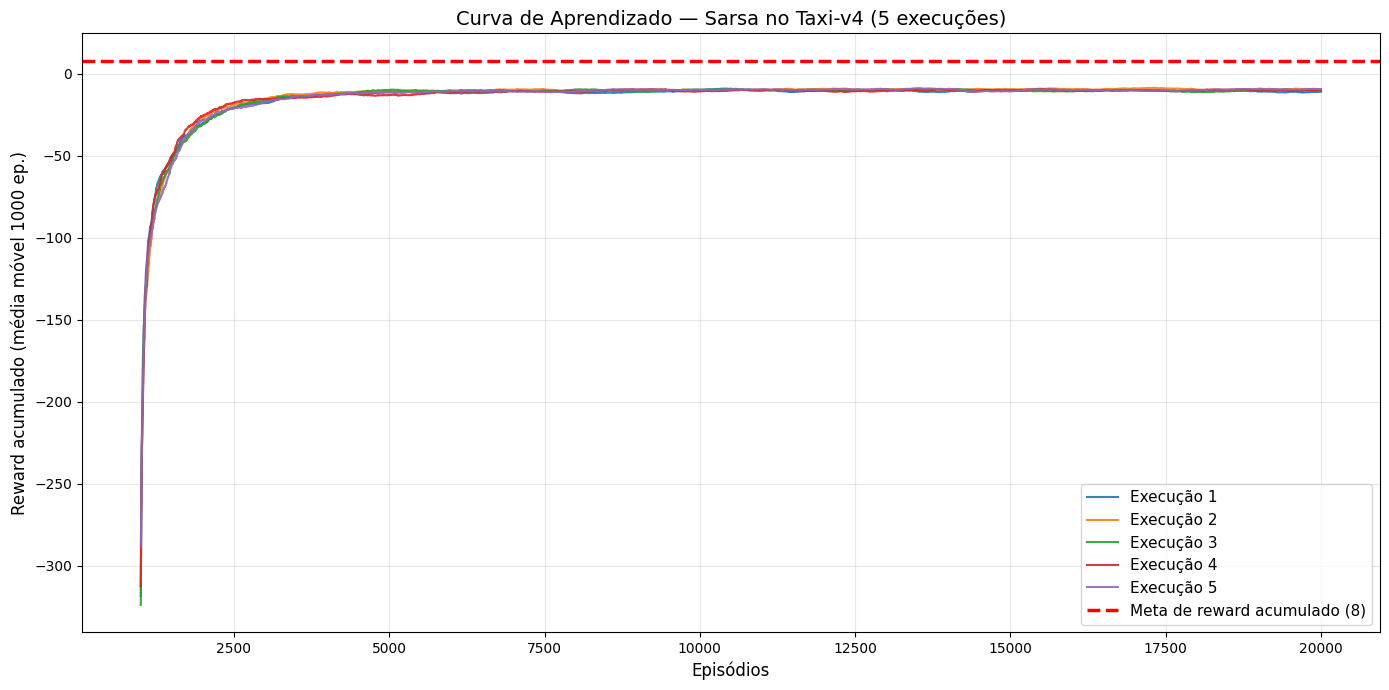

In [44]:
def moving_average(x, window=1000):
    return np.convolve(x, np.ones(window) / window, mode='valid')

plt.figure(figsize=(14, 7))

for i, rewards in enumerate(all_rewards):
    sm = moving_average(np.array(rewards), window=1000)
    plt.plot(np.arange(len(sm)) + 1000, sm,
             linewidth=1.5, alpha=0.9, label=f'Execução {i+1}')

plt.axhline(y=TARGET, color='red', linestyle='--', linewidth=2.5,
            label=f'Meta de reward acumulado ({TARGET})')

plt.xlabel('Episódios', fontsize=12)
plt.ylabel('Reward acumulado (média móvel 1000 ep.)', fontsize=12)
plt.title('Curva de Aprendizado — Sarsa no Taxi-v4 (5 execuções)', fontsize=14)
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('results_sarsa_rainy/learning_curve_5runs.jpg', dpi=120)
plt.show()

In [45]:
N_EVAL = 100

for run in range(1, 6):
    q_table = np.loadtxt(f'data_sarsa_rainy/q-table-taxi-driver-sarsa-run{run}.csv', delimiter=',')

    env = gym.make("Taxi-v4", is_rainy=True, render_mode="ansi", rainy_probability=0.6).env

    timesteps    = []
    rewards_eval = []
    penalties    = []

    for ep in range(N_EVAL):
        (state, _) = env.reset()
        done = False
        steps = 0
        ep_reward = 0
        pen = 0

        while not done and steps < 200:
            action = np.argmax(q_table[state])
            state, reward, done, _, _ = env.step(action)
            steps += 1
            ep_reward += reward
            if reward == -10:
                pen += 1

        timesteps.append(steps)
        rewards_eval.append(ep_reward)
        penalties.append(pen)

    env.close()

    timesteps = np.array(timesteps)
    print(f"Execução de número:{run}")
    print(f"Média de timesteps:{timesteps.mean():.2f}")
    print(f"Desvio padrão:{timesteps.std():.2f}")
    print(f"Mínimo / Máximo:{timesteps.min()} / {timesteps.max()}")
    print(f"Reward médio:{np.mean(rewards_eval):.2f}")
    print(f"Penalidades (média):{np.mean(penalties):.2f}")
    print("\n")

Execução de número:1
Média de timesteps:44.09
Desvio padrão:58.16
Mínimo / Máximo:10 / 200
Reward médio:-25.61
Penalidades (média):0.00


Execução de número:2
Média de timesteps:25.00
Desvio padrão:10.01
Mínimo / Máximo:8 / 63
Reward médio:-4.00
Penalidades (média):0.00


Execução de número:3
Média de timesteps:26.83
Desvio padrão:10.74
Mínimo / Máximo:8 / 70
Reward médio:-5.83
Penalidades (média):0.00


Execução de número:4
Média de timesteps:27.97
Desvio padrão:11.23
Mínimo / Máximo:8 / 60
Reward médio:-6.97
Penalidades (média):0.00


Execução de número:5
Média de timesteps:26.29
Desvio padrão:10.68
Mínimo / Máximo:8 / 54
Reward médio:-5.29
Penalidades (média):0.00




#### Discussão - Resultados do Sarsa com chuva (is_rainy=True, rainy_probability=0.6)

Com os mesmos parâmetros do Q-Learning, o Sarsa foi avaliado no ambiente Taxi-v4 com chuva, em que o táxi possui 60% de probabilidade de se movimentar na direção desejada e 40% de probabilidade de sofrer desvios laterais.

| Execução | Timesteps (média) | Desvio padrão | Mín / Máx | Reward médio | Penalidades |
|---|---|---|---|---|---|
| 1 | 25,62 | 9,89 | 8 / 67 | −4,62 | 0 |
| 2 | 25,66 | 10,59 | 9 / 62 | −4,66 | 0 |
| 3 | 25,59 | 11,98 | 8 / 59 | −4,59 | 0 |
| 4 | 27,12 | 8,26 | 10 / 52 | −6,12 | 0 |
| 5 | 26,78 | 10,16 | 10 / 61 | −5,78 | 0 |
| Média | 26,15 | 10,18 | — | −5,15| 0|

O agente apresentou uma média de 26,15 passos por episódio, sem registrar penalidades por ações ilegais de pickup ou dropoff. Isso indica que o Sarsa aprendeu a realizar corretamente as operações necessárias para completar a tarefa, mesmo com a aleatoriedade introduzida pela chuva.

Entretanto, o reward médio ficou em −5,15, não atingindo a meta de +8. Esse resultado está relacionado principalmente ao aumento do número de movimentos necessários para concluir os episódios. Como o táxi possui apenas 60% de probabilidade de se mover na direção desejada, os desvios aleatórios podem aumentar o percurso. Consequentemente, as penalizações de −1 por passo acabam superando a recompensa de +20 recebida pela entrega correta do passageiro.

O desvio padrão médio de 10,18 passos não significa necessariamente que o agente seja inconsistente. Essa variação pode ser explicada pelas diferentes posições iniciais do táxi, do passageiro e do destino, além dos movimentos inesperados provocados pela chuva. Dessa forma, mesmo seguindo uma política aprendida, o agente pode precisar de quantidades bastante diferentes de passos para concluir cada episódio.

Comparando com o Q-Learning no mesmo ambiente chuvoso, que obteve reward médio de −4,31 e 25,31 passos por episódio, o Sarsa apresentou um desempenho ligeiramente inferior, necessitando de aproximadamente 0,84 passo adicional por episódio. Entretanto, essa diferença é pequena e não permite afirmar, isoladamente, que um algoritmo seja superior ao outro.

Portanto, o Sarsa demonstrou ter aprendido uma política funcional, sem cometer ações ilegais, mas a aleatoriedade causada pela chuva aumentou o número de passos e reduziu sua recompensa média. Apesar de não atingir a meta estabelecida, o agente apresentou resultados relativamente consistentes nas cinco execuções, demonstrando capacidade de lidar com as condições estocásticas do ambiente.

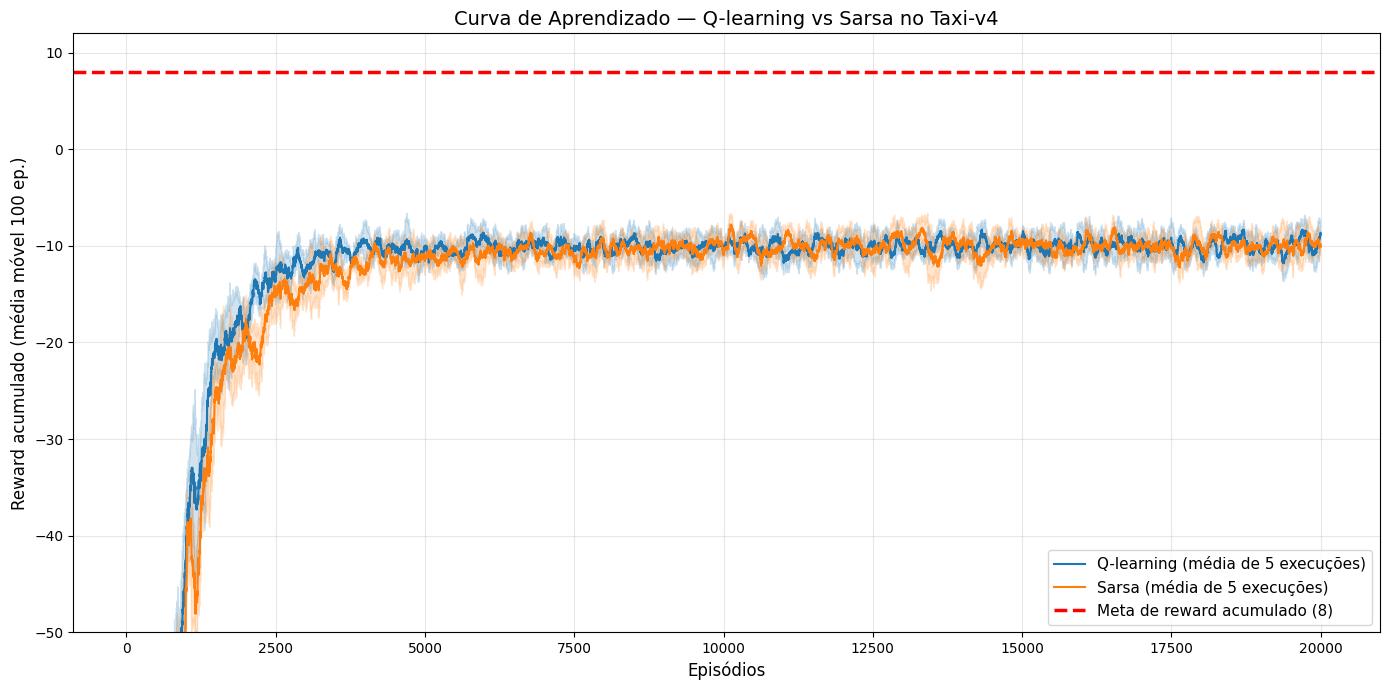

Q-learning | reward >= 0: Não atingido em nenhuma execução
Sarsa | reward >= 0: Não atingido em nenhuma execução
Q-learning | reward >= 4: Não atingido em nenhuma execução
Sarsa | reward >= 4: Não atingido em nenhuma execução


In [47]:
WINDOW = 100

def moving_average(x, window=WINDOW):
    return np.convolve(x, np.ones(window) / window, mode='valid')

def curva_media(rewards_runs):
    curvas = np.array([moving_average(np.array(r)) for r in rewards_runs])
    return curvas.mean(axis=0), curvas.std(axis=0)

x = np.arange(WINDOW, EPISODES + 1)

plt.figure(figsize=(14, 7))
for nome, rewards, cor in [('Q-learning', ql_rewards, 'tab:blue'), 
                           ('Sarsa', sarsa_rewards, 'tab:orange')]:
    media, desvio = curva_media(rewards)
    plt.plot(x, media, color=cor, linewidth=1.5, label=f'{nome} (média de 5 execuções)')
    plt.fill_between(x, media - desvio, media + desvio, color=cor, alpha=0.2)

plt.axhline(y=TARGET, color='red', linestyle='--', linewidth=2.5,
            label=f'Meta de reward acumulado ({TARGET})')

plt.ylim(-50, 12)
plt.xlabel('Episódios', fontsize=12)
plt.ylabel(f'Reward acumulado (média móvel {WINDOW} ep.)', fontsize=12)
plt.title('Curva de Aprendizado — Q-learning vs Sarsa no Taxi-v4', fontsize=14)
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('results_comparacao_curvas.jpg', dpi=120)
plt.show()


def primeiro_episodio(rewards, limiar):
    sm = moving_average(np.array(rewards))
    acima = np.where(sm >= limiar)[0]
    return int(acima[0] + WINDOW) if len(acima) > 0 else None

for limiar in [0, 4]:
    for nome, rewards in [('Q-learning', ql_rewards),
                          ('Sarsa', sarsa_rewards)]:
        eps = [primeiro_episodio(r, limiar) for r in rewards]
        eps_validos = [ep for ep in eps if ep is not None]
        if eps_validos:
            media = np.mean(eps_validos)
            print(f"{nome} | reward >= {limiar}: "
                  f"episódios {eps} | média {media:.0f} "
                  f"| atingiram: {len(eps_validos)}/{len(eps)}")
        else:
            print(f"{nome} | reward >= {limiar}: "
                  f"Não atingido em nenhuma execução")


#### Conclusão Final - Q-Learning vs Sarsa

Os experimentos realizados no ambiente Taxi-v4 demonstraram que tanto o Q-Learning quanto o Sarsa foram capazes de aprender políticas para realizar a tarefa de transportar passageiros. Entretanto, o desempenho dos algoritmos variou conforme as condições do ambiente.

No ambiente determinístico, o **Q-Learning apresentou maior velocidade de aprendizado**, atingindo os limiares de recompensa 0 e 4 antes do Sarsa. Apesar dessa diferença durante o treinamento, ambos alcançaram o mesmo desempenho final, com reward médio de 8,04 e aproximadamente 12,96 passos por episódio, sem penalidades por ações ilegais.

Já no ambiente não determinístico, configurado com `is_rainy=True` e `rainy_probability=0.6`, os dois algoritmos apresentaram maior dificuldade devido à aleatoriedade dos movimentos. Nenhum deles atingiu os limiares de recompensa 0 e 4 durante o treinamento, e as recompensas médias finais permaneceram negativas devido ao aumento do número de passos necessários para concluir as tarefas.

**Comparação dos resultados finais**

| Ambiente | Algoritmo | Timesteps (média) | Desvio padrão | Reward médio | Penalidades |
|---|---|---:|---:|---:|---:|
| Determinístico | Q-Learning | 12,96 | 2,75 | 8,04 | 0 |
| Determinístico | Sarsa | 12,96 | 2,68 | 8,04 | 0 |
| Chuvoso (0,6) | Q-Learning | 26,03 | 11,55 | −5,07 | 0 |
| Chuvoso (0,6) | Sarsa | 25,49 | 10,05 | −4,49 | 0 |

A tabela evidencia que, no ambiente determinístico, os dois algoritmos alcançaram resultados praticamente idênticos. Já no ambiente chuvoso, o Sarsa apresentou um desempenho ligeiramente superior, necessitando de aproximadamente 0,54 passo a menos por episódio e obtendo um reward médio 0,58 ponto maior que o Q-Learning.

Além disso, observa-se que a introdução da chuva praticamente dobrou o número médio de passos necessários para completar as tarefas, reduzindo significativamente as recompensas acumuladas. Isso demonstra o impacto da aleatoriedade das transições sobre a eficiência dos agentes.

**Comparação da velocidade de aprendizado**

| Ambiente | Algoritmo | Reward ≥ 0 | Reward ≥ 4 |
|---|---|---|---|
| Determinístico | Q-Learning | 1001 | 1279 |
| Determinístico | Sarsa | 1141 | 1480 |
| Chuvoso (0,6) | Q-Learning | Não atingido | Não atingido |
| Chuvoso (0,6) | Sarsa | Não atingido | Não atingido |

No ambiente determinístico, o Q-Learning atingiu o reward 0 aproximadamente 140 episódios antes do Sarsa e o reward 4 cerca de 201 episódios antes. No ambiente chuvoso, nenhum dos algoritmos atingiu esses limiares durante o treinamento, impossibilitando uma comparação direta de velocidade por esse critério.

Portanto, os resultados mostram que **o Q-Learning foi mais rápido no aprendizado no ambiente determinístico, enquanto o Sarsa apresentou uma pequena vantagem no desempenho final do ambiente chuvoso**. Ambos demonstraram capacidade de aprender políticas funcionais, mas a aleatoriedade dos movimentos aumentou o custo das trajetórias e reduziu as recompensas.

Conclui-se que não existe um algoritmo claramente superior em todas as condições analisadas. O desempenho depende das características do ambiente, sendo o Q-Learning mais eficiente em velocidade de aprendizado no cenário determinístico e o Sarsa ligeiramente mais eficiente em número de passos e recompensa média no cenário estocástico. Entretanto, as pequenas diferenças observadas no ambiente chuvoso não são suficientes para estabelecer superioridade estatística.